<a href="https://colab.research.google.com/github/Annrosejojue/DataScience/blob/main/SSA%20data%20analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Install seaborn for nicer plots
!pip install seaborn --quiet

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set plot style
sns.set(style="whitegrid", context="talk")


In [41]:
from google.colab import files
uploaded = files.upload()


Saving _Saturday STEM Academy Registration Fall 2025 (Responses) - Form Responses 1.csv to _Saturday STEM Academy Registration Fall 2025 (Responses) - Form Responses 1 (1).csv


In [42]:
from google.colab import files
uploaded = files.upload()


Saving Saturday STEM Academy Registration Spring 2025 (Responses) - Form Responses 1.csv to Saturday STEM Academy Registration Spring 2025 (Responses) - Form Responses 1 (1).csv


In [43]:
from google.colab import files
uploaded = files.upload()


Saving Saturday STEM Academy Registration Fall 2024 (Responses) - Form Responses 1.csv to Saturday STEM Academy Registration Fall 2024 (Responses) - Form Responses 1 (1).csv


In [44]:
from google.colab import files
uploaded = files.upload()


Saving _Saturday STEM Academy Registration Fall 2023 (Responses) - Form Responses 1.csv to _Saturday STEM Academy Registration Fall 2023 (Responses) - Form Responses 1 (1).csv


In [45]:
from google.colab import files
uploaded = files.upload()


Saving Saturday STEM Academy Registration Spring 2024 (Responses).xlsx to Saturday STEM Academy Registration Spring 2024 (Responses) (2).xlsx


In [46]:
from google.colab import files
uploaded = files.upload()

Saving _Saturday STEM Academy Registration Spring 2023 (Responses).xlsx to _Saturday STEM Academy Registration Spring 2023 (Responses) (2).xlsx


In [47]:
files_list = [
    "_Saturday STEM Academy Registration Fall 2025 (Responses) - Form Responses 1.csv",
    "Saturday STEM Academy Registration Spring 2025 (Responses) - Form Responses 1.csv",
    "Saturday STEM Academy Registration Fall 2024 (Responses) - Form Responses 1.csv",
    "_Saturday STEM Academy Registration Fall 2023 (Responses) - Form Responses 1.csv",
    "Saturday STEM Academy Registration Spring 2024 (Responses) (1).xlsx",
    "_Saturday STEM Academy Registration Spring 2023 (Responses) (1).xlsx"
]

dfs = []
for f in files_list:
    if f.endswith(".csv"):
        df = pd.read_csv(f)
    elif f.endswith(".xlsx"):
        df = pd.read_excel(f)
    else:
        print(f"Unsupported file format: {f}")
        continue
    df["source_file"] = f
    dfs.append(df)

data = pd.concat(dfs, ignore_index=True)

print("Combined shape:", data.shape)
data.head()



Combined shape: (532, 49)


,Timestamp,Email Address,Last Name,First Name,Which of the following best describes your child’s ethnicity (select all that apply)? This information helps us qualify for grant funding. Thank you for sharing,School District,School Name,Grade Level,Choose a class,Column 9,...,Column 2,Column 3,Column 4,Unnamed: 9,Unnamed: 11,Paid,CashNet,MU email confirmation,By providing your email you agree that the Mercy College Center for STEM Education (MCCSE) can reach out to you to participate in future data studies and to contact you about future STEM activities,Unnamed: 32
0,9/18/2025 16:17:22,noradoboshodge@gmail.com,Hodge,Aaron,"Black, White",Bedford Central School District,Bedford Hills Elementary School,3,NaN,Chemistreats: Food Fun through Chemistry,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaN,NaN
1,10/8/2025 22:01:47,kellysuyimib1@gmail.com,becerra,matias,Hispanic/Latino,Dobbs Ferry,Middle school,6,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaN,NaN
2,10/16/2025 19:53:44,colinyo@icloud.com,Keating,Colin,White,Yonkers,Sacred Heart High School,11,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaN,NaN
3,10/16/2025 20:01:09,emmetyo@icloud.com,Keating,Emmet,White,Yonkers,Sacred Heart High School,11,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaN,NaN
4,10/17/2025 16:04:20,nandiduperval@gmail.com,Fergusson,Noah,Black,Nyc,Success academy,5,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaN,NaN


In [48]:
# Standardize column names first (if not already done)
data.rename(columns=lambda x: x.strip().lower().replace(" ", "_"), inplace=True)

# Now you should have columns like 'last_name' and 'first_name'
# Count how many times each student appears across all files
repeat_counts = (
    data.groupby(["last_name", "first_name"])
    .size()
    .reset_index(name="count")
)

# Filter for students who appear more than once
repeats = repeat_counts[repeat_counts["count"] > 1]

print("Number of repeating students:", repeats.shape[0])
repeats


Number of repeating students: 21


,last_name,first_name,count
48,Becerra,Matias,2
52,Bhasin,Matthias,2
122,Galva,Edrain,2
124,Garcia,Adela,2
160,Hernandez,Elijah,2
169,Hodge,Aaron,2
200,Kubo,Emi,2
201,Lam,Abigail,2
210,Loayza,Scarlett,2
212,Lojano,Sebastian,2


In [49]:
# Count nulls in each column
data.isnull().sum()

# Specifically check nulls in first_name and last_name
null_names = data[data["first_name"].isnull() | data["last_name"].isnull()]
print("Rows with missing first or last name:", null_names.shape[0])
null_names


Rows with missing first or last name: 72


,timestamp,email_address,last_name,first_name,which_of_the_following_best_describes_your_child’s_ethnicity_(select_all_that_apply)?__this_information_helps_us_qualify_for_grant_funding.__thank_you_for_sharing,school_district,school_name,grade_level,choose_a_class,column_9,...,column_2,column_3,column_4,unnamed:_9,unnamed:_11,paid,cashnet,mu_email_confirmation,by_providing_your_email_you_agree_that_the_mercy_college_center_for_stem_education_(mccse)_can_reach_out_to_you_to_participate_in_future_data_studies_and_to_contact_you_about_future_stem_activities,unnamed:_32
138,NaN,NaN,78 Students,NaN,"49 (63%) Hispanic, 8 (10%) White, 11(14%) Blac...",8 Districts,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaN,NaN
139,NaN,NaN,NaN,NaN,NaN,"21(27%) dobbs Ferry, 2(3%) Bedford, 10(13%) Yo...",NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaN,NaN
140,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaN,NaN
141,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaN,NaN
142,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
527,NaT,NaN,NaN,NaN,NaN,1,Brooklyn,NaN,Dobbs Ferry Union Free School District,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaN,NaN
528,NaT,NaN,NaN,NaN,NaN,2,Bronx,NaN,District 8,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaN,NaN
529,NaT,NaN,NaN,NaN,NaN,NaN,NaN,6,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaN,NaN
530,NaT,NaN,NaN,NaN,NaN,1,Dobbs Ferry,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaN,NaN


In [50]:
# Remove rows where first_name or last_name is missing
data = data.dropna(subset=["first_name", "last_name"])


In [51]:
# Check duplicates based on first and last name
duplicates = data[data.duplicated(subset=["first_name", "last_name"], keep=False)]

print("Number of duplicate rows:", duplicates.shape[0])
duplicates.sort_values(by=["last_name", "first_name"])


Number of duplicate rows: 45


,timestamp,email_address,last_name,first_name,which_of_the_following_best_describes_your_child’s_ethnicity_(select_all_that_apply)?__this_information_helps_us_qualify_for_grant_funding.__thank_you_for_sharing,school_district,school_name,grade_level,choose_a_class,column_9,...,column_2,column_3,column_4,unnamed:_9,unnamed:_11,paid,cashnet,mu_email_confirmation,by_providing_your_email_you_agree_that_the_mercy_college_center_for_stem_education_(mccse)_can_reach_out_to_you_to_participate_in_future_data_studies_and_to_contact_you_about_future_stem_activities,unnamed:_32
122,2/28/2025 7:33:15,kellysuyimib1@gmail.com,Becerra,Matias,Hispanic/Latino,Dobbs Ferry,Spring hurts,5.0,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaN,NaN
206,10/16/2024 22:01:48,kellysuyimib1@gmail.com,Becerra,Matias,Hispanic/Latino,Dobbs Ferry,Spring hurts,5.0,NaN,NaN,...,mu email 10/18/24,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaN,NaN
237,9/25/2023 12:17:31,lara.bhasin@tsm.edu,Bhasin,Matthias,"Asian/Pacific Islander, White",Pocantico Hills Central School District,Pocantico Hills,7,NaN,NaN,...,NaN,NaN,NaN,NaN,The Wonders of DNA,Cashnet,NaN,NaT,NaN,NaN
425,2023-02-09 13:24:04.856000,lara.bhasin@tsm.edu,Bhasin,Matthias,"Asian/Pacific Islander, White",Pocantico Hills Central School District,Pocantico Hills,6,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT,Yes,conf. letter 2/9/23
126,2/28/2025 10:16:47,atzyrisgalva24@gmail.com,Galva,Edrain,Other,Dobbs ferry,Springhurst,4.0,NaN,You Makey Makey Me Want to Invent,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaN,NaN
211,10/18/2024 12:12:20,atzyrisgalva24@gmail.com,Galva,Edrain,Hispanic/Latino,Dobbs ferry,Springhurst,4.0,NaN,Why is it Raining? Weather and Water,...,mu email 10/18/24,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaN,NaN
36,10/29/2025 15:19:16,mcmd2007@hotmail.com,Garcia,Adela,Hispanic/Latino,New Rochelle NY,Columbus Elementary,5,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaN,NaN
353,2024-01-31 15:11:48.072000,mcmd2007@hotmail.com,Garcia,Adela,Hispanic/Latino,Westchester,Columbus Elementary School,3,NaN,NaN,...,NaN,NaN,NaN,You Makey Makey Me want to Invent!,NaN,NaN,Sandpiper,2024-02-02,NaN,NaN
210,10/18/2024 12:09:57,vjsmiracle1002@gmail.com,Hernandez,Elijah,Hispanic/Latino,Dobbs Ferry,Springhurst Elementary,5.0,NaN,NaN,...,mu email 10/18/24,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaN,NaN
298,10/25/2023 12:15:12,vjsmiracle1002@gmail.com,Hernandez,Elijah,Hispanic/Latino,Dobbs Ferry Union Free School District,Springhurst Elementary School,4,NaN,NaN,...,NaN,NaN,NaN,You Makey Makey Me want to Invent!,NaN,Con Ed,NaN,NaT,NaN,NaN


In [52]:
# Drop duplicates, keeping the first occurrence
data = data.drop_duplicates(subset=["first_name", "last_name"], keep="first")

print("Shape after removing duplicates:", data.shape)


Shape after removing duplicates: (436, 49)


In [53]:
# Confirm no nulls and no duplicates remain
print("Nulls after cleaning:", data[["first_name", "last_name"]].isnull().sum().sum())
print("Duplicates after cleaning:", data.duplicated(subset=["first_name", "last_name"]).sum())


Nulls after cleaning: 0
Duplicates after cleaning: 0


Graphs & Insights by Column
1. Timestamp
Purpose: Show registration trends over time.

Graph: Line chart of counts per day/week.

/tmp/ipython-input-3838453377.py:29: UserWarning: Glyph 128197 (\N{CALENDAR}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128197 (\N{CALENDAR}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


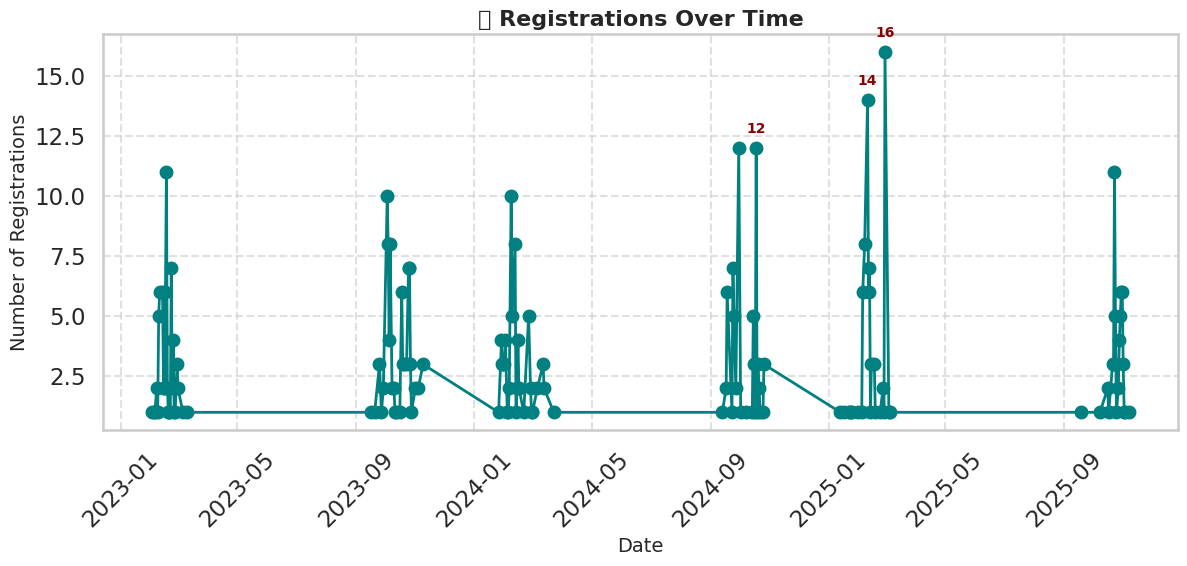

In [54]:
# Convert timestamp column to datetime
data['timestamp'] = pd.to_datetime(data['timestamp'])

# Group by date and count registrations
registrations_over_time = data.groupby(data['timestamp'].dt.date).size()

# Plot with improved formatting
plt.figure(figsize=(12,6))
plt.plot(registrations_over_time.index, registrations_over_time.values,
         marker='o', linestyle='-', linewidth=2, color='teal')

# Add labels and title
plt.title("📅 Registrations Over Time", fontsize=16, fontweight='bold')
plt.xlabel("Date", fontsize=14)
plt.ylabel("Number of Registrations", fontsize=14)

# Rotate x-axis labels for readability
plt.xticks(rotation=45)

# Add grid for clarity
plt.grid(True, linestyle='--', alpha=0.6)

# Annotate peak registration days (top 3)
peak_days = registrations_over_time.sort_values(ascending=False).head(3)
for date, count in peak_days.items():
    plt.text(date, count+0.5, str(count), ha='center', va='bottom',
             fontsize=10, fontweight='bold', color='darkred')

plt.tight_layout()
plt.show()


Email Address
Purpose: Identify unique registrants and duplicates.

Graph: Bar chart of duplicate counts.

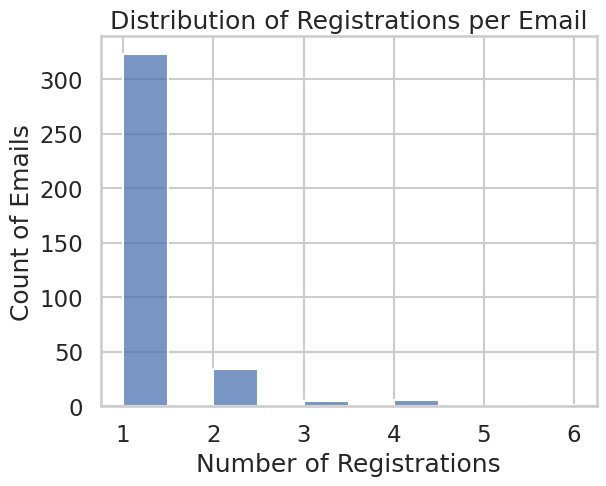

In [55]:
email_counts = data['email_address'].value_counts()
sns.histplot(email_counts, bins=10)
plt.title("Distribution of Registrations per Email")
plt.xlabel("Number of Registrations")
plt.ylabel("Count of Emails")
plt.show()

Ethnicity
Purpose: Diversity representation (important for grant funding).

Graph: Pie chart or bar chart of ethnicities.

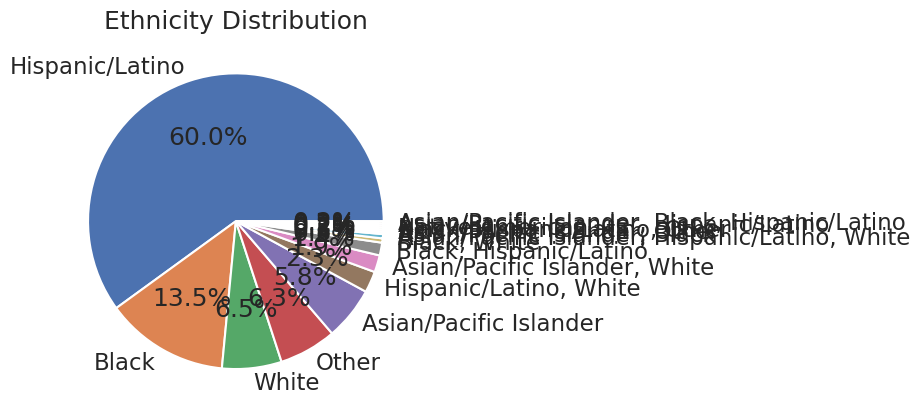

In [56]:
ethnicity_counts = data['which_of_the_following_best_describes_your_child’s_ethnicity_(select_all_that_apply)?__this_information_helps_us_qualify_for_grant_funding.__thank_you_for_sharing'].value_counts()
ethnicity_counts.plot(kind='pie', autopct='%1.1f%%', title="Ethnicity Distribution")
plt.ylabel("")
plt.show()

Grouped small slices into “Other” so the chart isn’t cluttered.

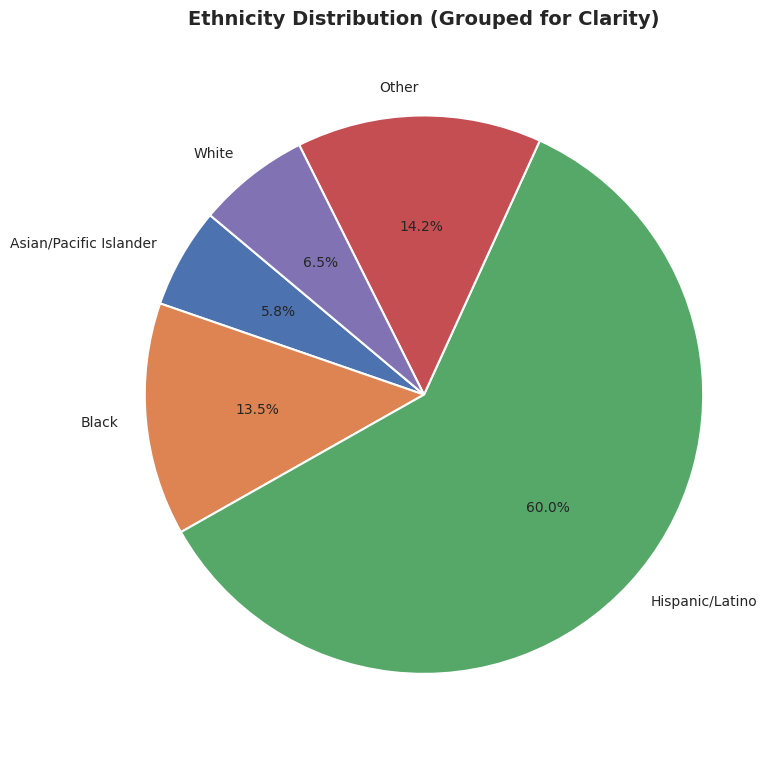

In [57]:
# Clean column name first
ethnicity_col = "which_of_the_following_best_describes_your_child’s_ethnicity_(select_all_that_apply)?__this_information_helps_us_qualify_for_grant_funding.__thank_you_for_sharing"

# Count values
ethnicity_counts = data[ethnicity_col].value_counts()

# Group smaller slices into "Other" for clarity
threshold = 5  # minimum % to show separately
total = ethnicity_counts.sum()
ethnicity_cleaned = ethnicity_counts.copy()

# Replace small slices with "Other"
ethnicity_cleaned = ethnicity_cleaned.groupby(
    ethnicity_cleaned.index.map(lambda x: x if ethnicity_counts[x] / total * 100 >= threshold else "Other")
).sum()

# Plot pie chart
plt.figure(figsize=(8, 8))
plt.pie(
    ethnicity_cleaned.values,
    labels=ethnicity_cleaned.index,
    autopct="%1.1f%%",
    startangle=140,
    textprops={"fontsize": 10}
)
plt.title("Ethnicity Distribution (Grouped for Clarity)", fontsize=14, fontweight="bold")
plt.axis("equal")
plt.tight_layout()
plt.show()


School District
Purpose: Identify which districts send the most students.

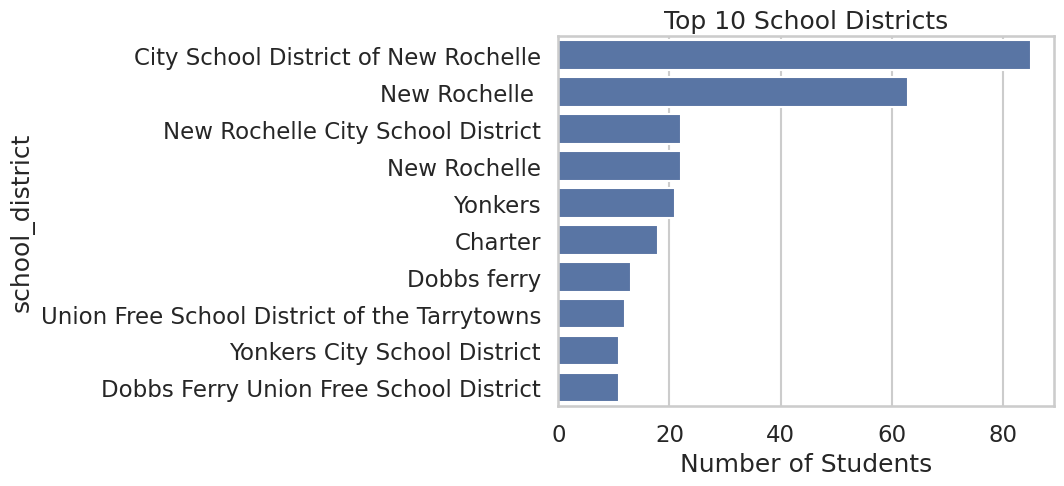

In [58]:
district_counts = data['school_district'].value_counts().head(10)
sns.barplot(y=district_counts.index, x=district_counts.values)
plt.title("Top 10 School Districts")
plt.xlabel("Number of Students")
plt.show()

standardize district names before plotting

In [60]:
# Dictionary to unify district names
district_map = {
    # Ardsley
    "ardsley": "Ardsley",
    "ardsley_union_free_school_district": "Ardsley",

    # Bedford
    "bedford_central_school_district": "Bedford Central",

    # Briarcliff
    "briarcliff": "Briarcliff",
    "briarcliff_manor": "Briarcliff",

    # CSDNR (short for City School District of New Rochelle)
    "csdnr": "New Rochelle",
    "city_school_district_of_new_rochelle": "New Rochelle",
    "city_school_district_of_new_rochelle": "New Rochelle",
    "district_of_new_rochelle": "New Rochelle",
    "new_rochelle": "New Rochelle",
    "new_rochelle_ny": "New Rochelle",
    "new_rochelle_city_school_district": "New Rochelle",
    "new_rochelle_school_district": "New Rochelle",
    "new_rocchelle": "New Rochelle",

    # Dobbs Ferry
    "dobbs": "Dobbs Ferry",
    "dobbs_ferry": "Dobbs Ferry",
    "dobbs_ferry_school_district": "Dobbs Ferry",
    "dobbs_ferry_union_free_school_district": "Dobbs Ferry",
    "dobbs_ferry_springhurst_elementary_school": "Dobbs Ferry",

    # Greenburgh
    "greenburgh_central_school_district": "Greenburgh Central",

    # Mount Vernon
    "mount_vernon": "Mount Vernon",

    # Ossining
    "ossining": "Ossining",

    # Port Chester
    "porchester": "Port Chester",
    "port_chester": "Port Chester",
    "port_chester_ny": "Port Chester",
    "port_chester_public_schools": "Port Chester",
    "port_chester_school_district": "Port Chester",

    # Tarrytown
    "tarrytown": "Tarrytown",
    "tarrytown_district": "Tarrytown",
    "union_free_school_district_of_the_tarrytowns": "Tarrytown",

    # Valley Stream
    "valley_stream_central_high_school_district": "Valley Stream",
    "valley_stream_union_free_school_district_13": "Valley Stream",

    # Westchester
    "weschester": "Westchester",
    "westchester": "Westchester",

    # White Plains
    "white_plains": "White Plains",

    # Yonkers
    "yonker_public_schools": "Yonkers",
    "yonkers": "Yonkers",
    "yonkers_city_school_district": "Yonkers",
    "yonkers_public_school": "Yonkers",
    "yonkers_public_schools": "Yonkers",
    "yonkers_city_school": "Yonkers",
}


In [61]:
# Clean up text: lowercase, strip spaces, replace special chars
data["school_district"] = (
    data["school_district"]
    .str.lower()
    .str.strip()
    .str.replace(r"[^\w\s]", "", regex=True)
    .str.replace(" ", "_")
)

# Apply mapping
data["school_district"] = data["school_district"].map(district_map).fillna(data["school_district"])


/tmp/ipython-input-682928846.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(y=district_counts.index, x=district_counts.values, palette="Blues_r")


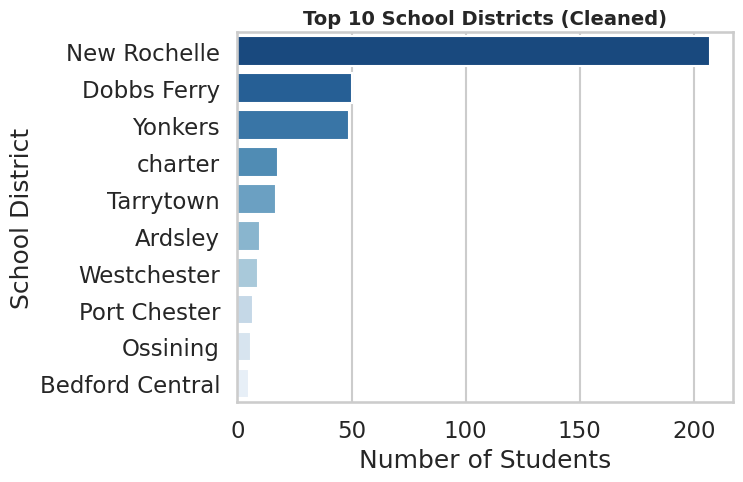

In [62]:
district_counts = data["school_district"].value_counts().head(10)

sns.barplot(y=district_counts.index, x=district_counts.values, palette="Blues_r")
plt.title("Top 10 School Districts (Cleaned)", fontsize=14, fontweight="bold")
plt.xlabel("Number of Students")
plt.ylabel("School District")
plt.show()


Purpose: See which schools are most engaged.

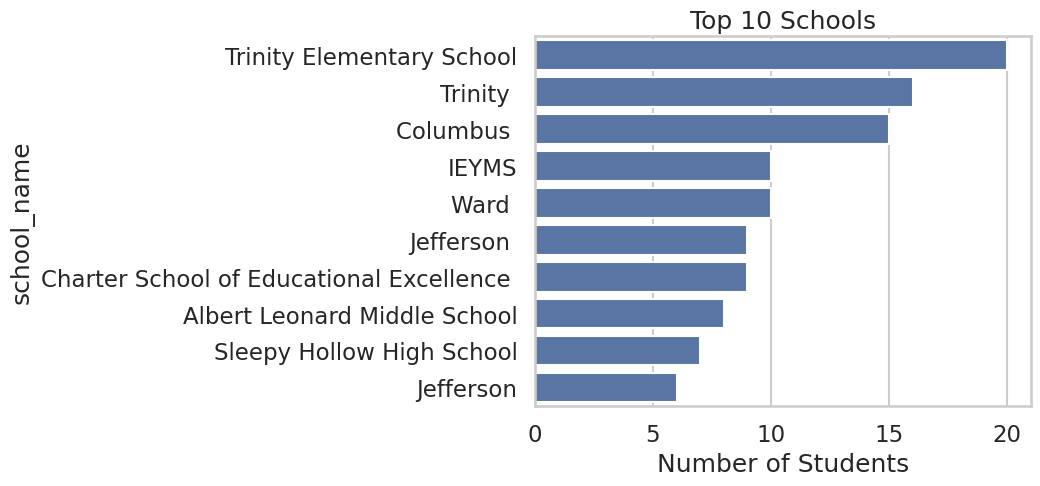

In [63]:
school_counts = data['school_name'].value_counts().head(10)
sns.barplot(y=school_counts.index, x=school_counts.values)
plt.title("Top 10 Schools")
plt.xlabel("Number of Students")
plt.show()

In [74]:
# Returns a NumPy array of unique school names
unique_schools = data['school_name'].unique()
print(unique_schools)


['Bedford Hills Elementary School' 'Middle school '
 'Sacred Heart High School ' 'Sacred Heart High School' 'Success academy '
 'Isaac Young Middle School ' 'Isaac E Young Middle School '
 'Issac E. Young Middle school' 'Charles E. Gorton' 'Jefferson'
 'Sleepy Hollow High School' 'Justice Sonia Sotomayor Community School'
 'Jefferson Elementary School ' 'Kent elementary school'
 'Todd Elementary ' 'Jefferson ES' 'Issac'
 'Justici Sonia Sotomayo Community School' 'Pearls Hawthorne'
 'Pearls Hawthorne ' 'Fox Lane Middle School' 'PEARLS Hawthorne'
 'Sonia Sotomayor' 'PEARLS' 'Pearls Hawthorn school '
 'Columbus Elementary School ' 'Barrack Obama school for social justice '
 'Columbus ' 'Springhurst Elementary ' 'Barack Obama' 'Columbus'
 'Columbus Elementary' 'Pearl’s hawthorn ' 'Springhurst Elementary School'
 'DFMS' 'Gorton high school ' 'high school' 'Springhurts'
 'Ardsley middle school ' 'Ardsley middle school'
 'Justice Sonia Sotomayor Community School ' 'Gorton High School '
 'Gort

In [102]:
school_map = {
    # Trinity Elementary
    "trinity": "Trinity Elementary School",
    "trinity_elementary_school": "Trinity Elementary School",
    "trinity elementary school": "Trinity Elementary School",
    "trinity school": "Trinity Elementary School",
    "trinity elementary": "Trinity Elementary School",
    "trinity elementaryh": "Trinity Elementary School",
    "trinty": "Trinity Elementary School",

    # Springhurst Elementary
    "springhurst": "Springhurst Elementary School",
    "springhurst_elementary_school": "Springhurst Elementary School",
    "springhurts": "Springhurst Elementary School",
    "springhurts elementary school": "Springhurst Elementary School",
    "springurts elemetary school": "Springhurst Elementary School",
    "springhurt": "Springhurst Elementary School",
    "spring hurts": "Springhurst Elementary School",
    "springhurts elementary": "Springhurst Elementary School",

    # Isaac E. Young Middle School
    "ieyms": "Isaac E Young Middle School",
    "ieyms ": "Isaac E Young Middle School",
    "iey": "Isaac E Young Middle School",
    "isaac": "Isaac E Young Middle School",
    "issac": "Isaac E Young Middle School",
    "issac e. young middle school": "Isaac E Young Middle School",
    "isaac young middle school": "Isaac E Young Middle School",
    "isaac e young middle school": "Isaac E Young Middle School",
    "isaac e. young middle school ": "Isaac E Young Middle School",
    "isaac middle school": "Isaac E Young Middle School",
    "isaac e you g middle school": "Isaac E Young Middle School",
    "isaac e. young middle school": "Isaac E Young Middle School",
    "isaac e young": "Isaac E Young Middle School",
    "isaac e young middle": "Isaac E Young Middle School",

    # Albert Leonard Middle School
    "alms": "Albert Leonard Middle School",
    "ALMS": "Albert Leonard Middle School",
    "albert": "Albert Leonard Middle School",
    "albert leonard middle school": "Albert Leonard Middle School",
    "albert leonard ": "Albert Leonard Middle School",
    "albert leonard middle school": "Albert Leonard Middle School",
    "albert leonard middle school ": "Albert Leonard Middle School",
    "albert leonard middle": "Albert Leonard Middle School",
    "albert leonard middle school ": "Albert Leonard Middle School",

    # John F. Kennedy Elementary
    "jfk elementary": "John F Kennedy Elementary School",
    "jfk elementary school": "John F Kennedy Elementary School",
    "john f kennedy": "John F Kennedy Elementary School",
    "jfk": "John F Kennedy Elementary School",

    # Columbus Elementary
    "columbus": "Columbus Elementary School",
    "columbus ": "Columbus Elementary School",
    "columbus elementary school": "Columbus Elementary School",
    "columbus elementary": "Columbus Elementary School",
    "columbus elementary ": "Columbus Elementary School",
    "columbus elementery school": "Columbus Elementary School",
    "colombus elementary": "Columbus Elementary School",

    # Jefferson Elementary
    "jefferson": "Jefferson Elementary School",
    "jefferson elementary school ": "Jefferson Elementary School",
    "jefferson es": "Jefferson Elementary School",
    "jefferson elementary school": "Jefferson Elementary School",
    "jefferson elementary": "Jefferson Elementary School",

    # Washington Irving
    "washington irving school ": "Washington Irving School",
    "washington irving": "Washington Irving School",
    "washington irving school": "Washington Irving School",
    "washington irving intermediate school": "Washington Irving School",

    # Sleepy Hollow High
    "sleepy hollow high school": "Sleepy Hollow High School",
    "sleepy hollow highschool": "Sleepy Hollow High School",
    "sleepy hollow high school ": "Sleepy Hollow High School",
    "sleepy hollow highschool ": "Sleepy Hollow High School",

    # Emblaze Academy
    "emblaze academy": "Emblaze Academy Charter School",
    "emblaze academy charter school": "Emblaze Academy Charter School",
    "emblaze academic chapter school": "Emblaze Academy Charter School",
    "emblaze academy charter school ": "Emblaze Academy Charter School",
    "emblaze academy ": "Emblaze Academy Charter School",

    # Charter School of Educational Excellence
    "charter school of educational excellence": "Charter School of Educational Excellence",
    "charter school of educational excellence ": "Charter School of Educational Excellence",
    "charter school for educational excellence": "Charter School of Educational Excellence",
    "charter school of education excellence": "Charter School of Educational Excellence",
    "charter school of education exellence": "Charter School of Educational Excellence",
    "charter school of educational exallenc": "Charter School of Educational Excellence",
    "charter school of educational excellent": "Charter School of Educational Excellence",
    "csee": "Charter School of Educational Excellence",
    "csee ": "Charter School of Educational Excellence",
    "csee high school": "Charter School of Educational Excellence",
    "charter school of educational excellence high school": "Charter School of Educational Excellence",
    "charter school of educational excellence hs": "Charter School of Educational Excellence",
}

In [103]:
import re
import pandas as pd

def clean_school_name(name):
    if pd.isna(name):
        return None
    # Ensure it's a string before applying string methods
    name = str(name)
    # lowercase
    name = name.lower()
    # strip leading/trailing spaces
    name = name.strip()
    # remove punctuation
    name = re.sub(r"[^\w\s]", "", name)
    # collapse multiple spaces
    name = re.sub(r"\s+", " ", name)
    return name



In [109]:
# Apply cleaning function to the school_name column
data['school_name_cleaned'] = data['school_name'].apply(clean_school_name)

In [110]:
# Map cleaned names to canonical names
data['school_name_final'] = data['school_name_cleaned'].map(school_map).fillna(data['school_name_cleaned'])

In [111]:
# Check unique cleaned school names
print(data['school_name_final'].unique())

# Count occurrences
print(data['school_name_final'].value_counts().head(10))

['bedford hills elementary school' 'middle school'
 'sacred heart high school' 'success academy'
 'Isaac E Young Middle School' 'issac e young middle school'
 'charles e gorton' 'Jefferson Elementary School'
 'Sleepy Hollow High School' 'justice sonia sotomayor community school'
 'kent elementary school' 'todd elementary'
 'justici sonia sotomayo community school' 'pearls hawthorne'
 'fox lane middle school' 'sonia sotomayor' 'pearls'
 'pearls hawthorn school' 'Columbus Elementary School'
 'barrack obama school for social justice' 'springhurst elementary'
 'barack obama' 'pearls hawthorn' 'springhurst elementary school' 'dfms'
 'gorton high school' 'high school' 'ardsley middle school'
 'mercy university' None 'claremont' 'davis'
 'Albert Leonard Middle School' 'thomas edisson school'
 'Trinity Elementary School' 'Charter School of Educational Excellence'
 'barnard' 'charter school of educational excellence highschool' 'ward'
 'John F Kennedy Elementary School' 'pennington'
 'dobbs fer

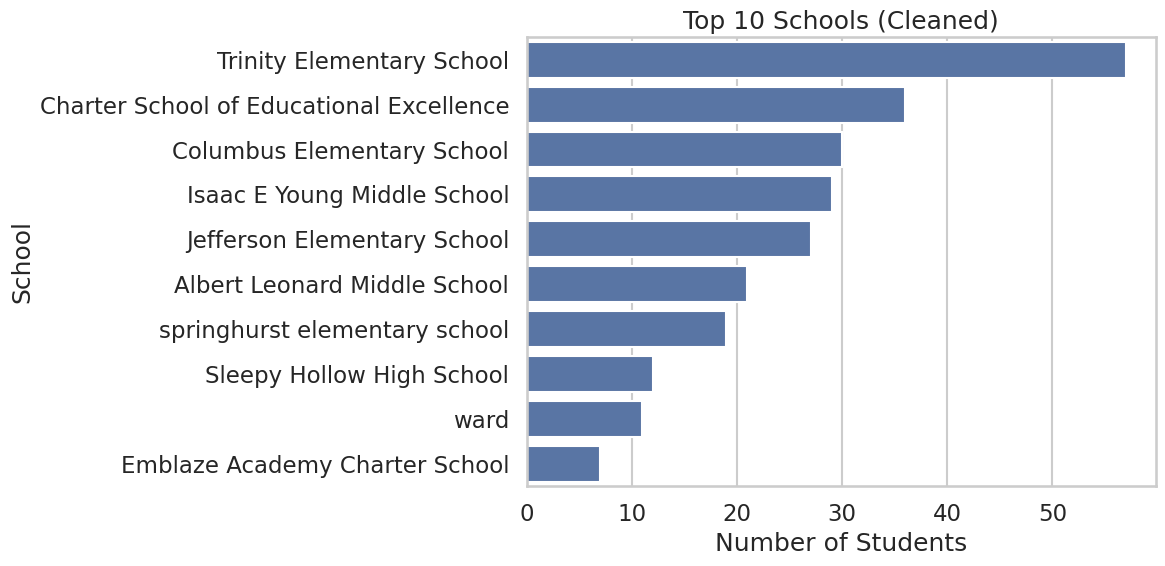

In [112]:
school_counts = data['school_name_final'].value_counts().head(10)

plt.figure(figsize=(12, 6))
sns.barplot(y=school_counts.index, x=school_counts.values)
plt.title("Top 10 Schools (Cleaned)")
plt.xlabel("Number of Students")
plt.ylabel("School")
plt.tight_layout()
plt.show()

Grade Level
Purpose: Age/grade distribution of participants.

/tmp/ipython-input-1554177019.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='grade_level_cleaned', data=data, order=plot_order, palette='viridis')


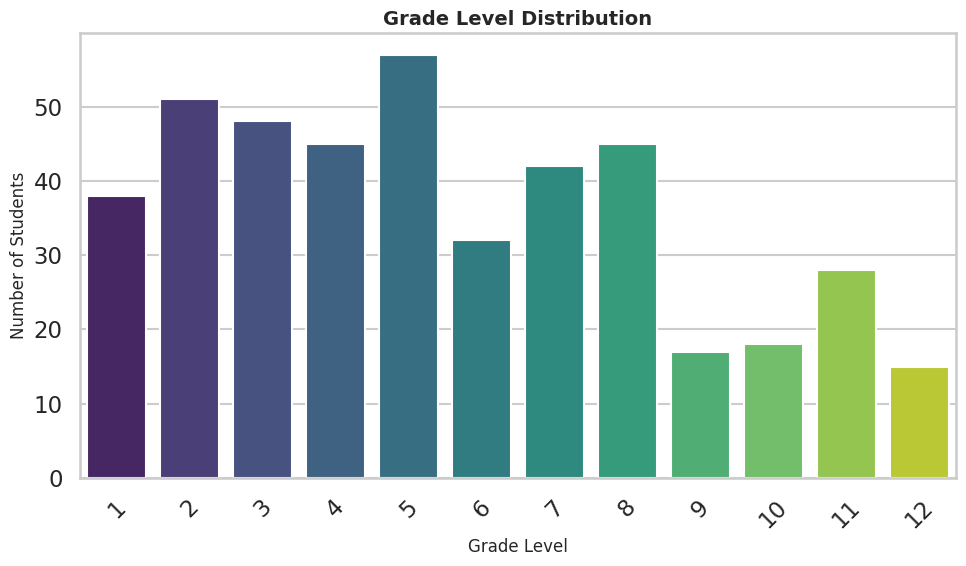

In [67]:
import numpy as np

def clean_grade_level(grade):
    grade_str = str(grade).strip().lower()
    if grade_str == 'homeschool':
        return grade_str
    try:
        # Check if it's a number
        num_grade = pd.to_numeric(grade_str)
        # Only keep integer grade levels (e.g., 5, not 5.5 or other non-integer floats)
        if num_grade == int(num_grade):
            return int(num_grade)
        else:
            return np.nan # Not an integer grade
    except ValueError:
        return np.nan # Not a number and not 'homeschool'

# Apply the cleaning function to create a new column
data['grade_level_cleaned'] = data['grade_level'].apply(clean_grade_level)

# Get unique valid grades and separate them for sorting
unique_cleaned_grades = data['grade_level_cleaned'].dropna().unique().tolist()

numeric_part = [g for g in unique_cleaned_grades if isinstance(g, int)]
string_part = [g for g in unique_cleaned_grades if isinstance(g, str)]

numeric_part.sort()
plot_order = [str(g) for g in numeric_part] + string_part

# Plot using the cleaned column and the custom order
plt.figure(figsize=(10, 6))
sns.countplot(x='grade_level_cleaned', data=data, order=plot_order, palette='viridis')
plt.title("Grade Level Distribution", fontsize=14, fontweight='bold')
plt.xlabel("Grade Level", fontsize=12)
plt.ylabel("Number of Students", fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Choose a Class
Purpose: Popularity of classes offered.

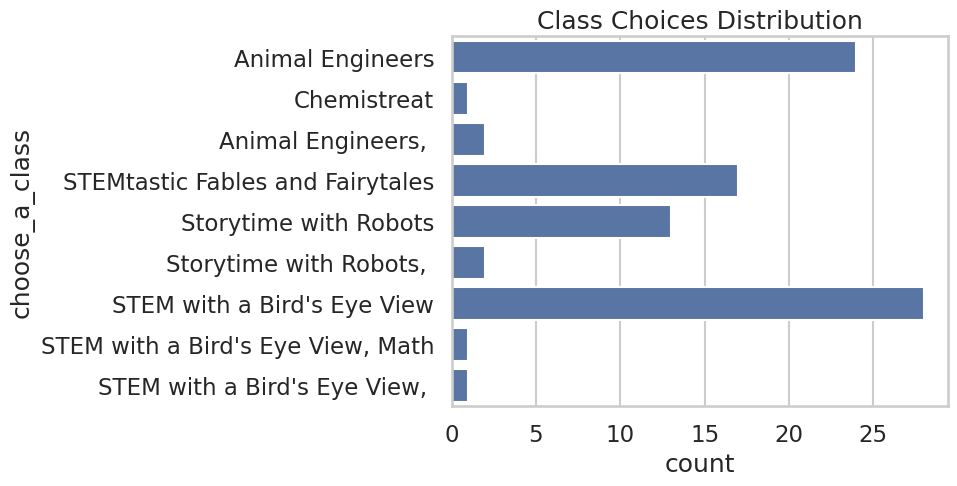

In [68]:
sns.countplot(y='choose_a_class', data=data)
plt.title("Class Choices Distribution")
plt.show()

last two entries in your class choices chart are duplicates caused by trailing commas or inconsistent formatting

quick cleaning step before plotting

In [69]:
# Clean trailing commas and whitespace
data['choose_a_class'] = (
    data['choose_a_class']
    .astype(str)
    .str.strip()
    .str.rstrip(',')
)

# Normalize "Storytime with Robots" entries
data['choose_a_class'] = data['choose_a_class'].replace({
    "Storytime with Robots,": "Storytime with Robots"
})


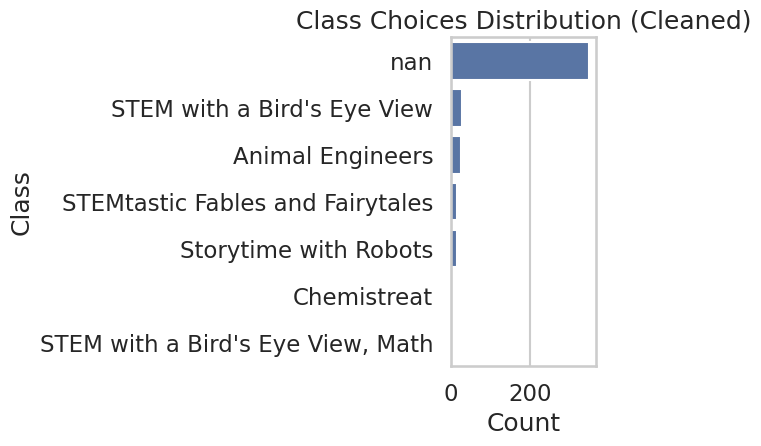

In [70]:
sns.countplot(y='choose_a_class', data=data, order=data['choose_a_class'].value_counts().index)
plt.title("Class Choices Distribution (Cleaned)")
plt.xlabel("Count")
plt.ylabel("Class")
plt.tight_layout()
plt.show()


In [71]:
# Count missing or blank class choices
missing_class = data[
    data['choose_a_class'].isnull() |
    (data['choose_a_class'].str.lower().isin(['', 'nan']))
]

print("Number of students who did not choose a class:", missing_class.shape[0])


Number of students who did not choose a class: 347


In [114]:
import re
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set(style="whitegrid", context="talk")

# Helper: detect class-choice columns per file (handles varied naming)
def get_class_columns(df):
    cols = []
    for c in df.columns:
        lc = c.lower()
        if ("choose" in lc and "class" in lc) or re.fullmatch(r"column[ _]*\d+", lc):
            cols.append(c)
    return cols

# Helper: clean and normalize class labels
def clean_choice(x):
    if pd.isna(x):
        return None
    s = str(x).strip().rstrip(",")  # trim spaces and trailing commas
    if s == "" or s.lower() == "nan":
        return None
    # Minimal normalization map for known duplicates
    normalized = {
        "storytime with robots": "Storytime with Robots",
        "storytime with robots,": "Storytime with Robots",
        "animal engineers": "Animal Engineers",
        "animal engineers,": "Animal Engineers",
        "stemtastic fables and fairytales": "STEMtastic Fables and Fairytales",
        "chemistreat": "Chemistreat",
        "you makey makey me want to invent": "You Makey Makey Me Want to Invent",
        "everyday stem hero: health basics in the nursing lab and cpr certification": "Everyday STEM Hero: Health Basics in the Nursing Lab and CPR Certification",
        "everyday stem hero: health basics in the nursing lab, with cpr certification": "Everyday STEM Hero: Health Basics in the Nursing Lab and CPR Certification"

    }
    key = s.lower()
    return normalized.get(key, s)

All detected class-choice columns in the combined dataset: ['choose_a_class', 'column_9', 'choose_a_class.1', 'column_11', 'choose_a_class.2', 'column_1', 'column_2', 'column_3', 'column_4']


/tmp/ipython-input-377536478.py:6: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  cleaned_choices_df = data[all_class_cols].applymap(clean_choice)
/tmp/ipython-input-377536478.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(y=overall_class_counts.index, x=overall_class_counts.values, palette="viridis")


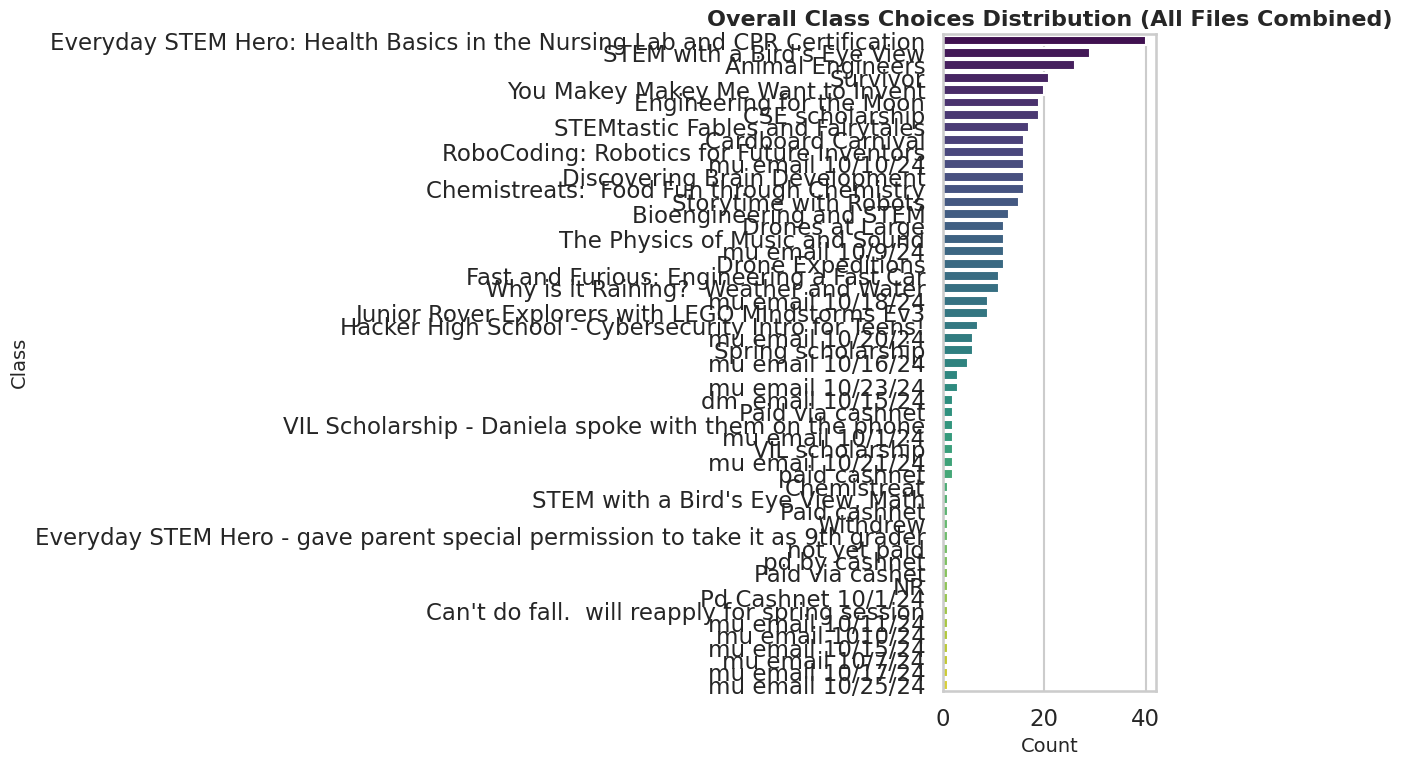

/tmp/ipython-input-377536478.py:34: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(y=overall_status.index, x=overall_status.values, palette=["green", "red"])


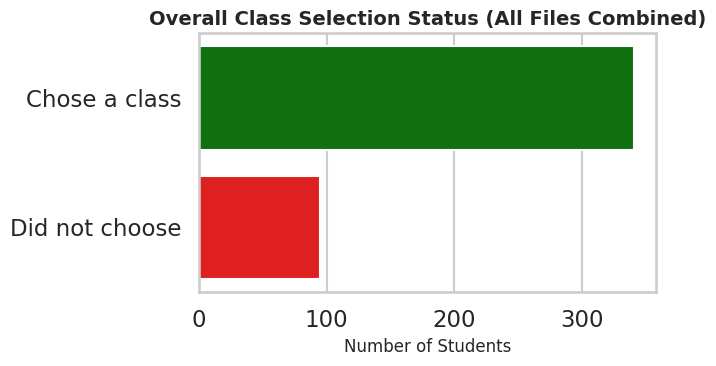


--- Overall Summary ---
Total unique students (after cleaning): 436
Total students who chose at least one class: 341
Total students who did not choose a class: 95

Top 10 Overall Most Popular Classes:
 - Everyday STEM Hero: Health Basics in the Nursing Lab and CPR Certification: 40
 - STEM with a Bird's Eye View: 29
 - Animal Engineers: 26
 - Survivor: 21
 - You Makey Makey Me Want to Invent: 20
 - Engineering for the Moon: 19
 - CSE scholarship: 19
 - STEMtastic Fables and Fairytales: 17
 - Cardboard Carnival: 16
 - RoboCoding: Robotics for Future Inventors: 16


In [116]:
# Identify all potential class choice columns in the entire dataset
all_class_cols = get_class_columns(data)
print(f"All detected class-choice columns in the combined dataset: {all_class_cols}")

# Apply cleaning to all relevant columns
cleaned_choices_df = data[all_class_cols].applymap(clean_choice)

# Melt the DataFrame to get a single Series of all chosen classes, dropping None values
all_chosen_classes = cleaned_choices_df.melt(value_name="class_choice")["class_choice"].dropna()

# Count the occurrences of each class
overall_class_counts = all_chosen_classes.value_counts()

# Plot overall class popularity
plt.figure(figsize=(12, 8))
sns.barplot(y=overall_class_counts.index, x=overall_class_counts.values, palette="viridis")
plt.title("Overall Class Choices Distribution (All Files Combined)", fontsize=16, fontweight="bold")
plt.xlabel("Count", fontsize=14)
plt.ylabel("Class", fontsize=14)
plt.tight_layout()
plt.show()

# Count students who did NOT choose any class (all class columns empty/None for a given row)
# This requires checking the original 'cleaned_choices_df' before melting
no_choice_mask_overall = cleaned_choices_df.apply(
    lambda row: all(x is None for x in row), axis=1
)
did_not_choose_overall = int(no_choice_mask_overall.sum())
chose_any_overall = int(len(data) - did_not_choose_overall)

# Plot chose vs. did not choose for the overall dataset
overall_status = pd.Series({"Chose a class": chose_any_overall, "Did not choose": did_not_choose_overall})
plt.figure(figsize=(7, 4))
sns.barplot(y=overall_status.index, x=overall_status.values, palette=["green", "red"])
plt.title("Overall Class Selection Status (All Files Combined)", fontsize=14, fontweight="bold")
plt.xlabel("Number of Students", fontsize=12)
plt.ylabel("")
plt.tight_layout()
plt.show()

print("\n--- Overall Summary ---")
print(f"Total unique students (after cleaning): {len(data)}")
print(f"Total students who chose at least one class: {chose_any_overall}")
print(f"Total students who did not choose a class: {did_not_choose_overall}")

if len(overall_class_counts) > 0:
    print("\nTop 10 Overall Most Popular Classes:")
    for cls, cnt in overall_class_counts.head(10).items():
        print(f" - {cls}: {cnt}")